# Lab 10C (optional): Gram Matrices, Texture and Style

## ✅ Solution version

All `???` gaps are filled in, and a **Solution and discussion** box follows every set of questions. Your own numbers will differ somewhat from run to run; what matters is whether you can explain the patterns.

**Before you start: Runtime → Change runtime type → GPU.**

This is the optional third notebook. Do it if you have finished 10A and 10B (and your iteration log),
or at home. It uses the same "optimise the input" idea as 10A, now with a loss that compares
**statistics** of feature maps instead of the feature maps themselves.

| Part | You will… |
|---|---|
| 1. The Gram matrix | implement it, prove that it ignores *where* features are, and measure whether it captures "style" |
| 2. Texture synthesis | create new textures from noise, and find out what the choice of layers does |
| 3. Neural style transfer | combine content and style, and explore the trade-off between them |
| 4. Exam-style questions | check your understanding |

## Setup

Using device: cuda


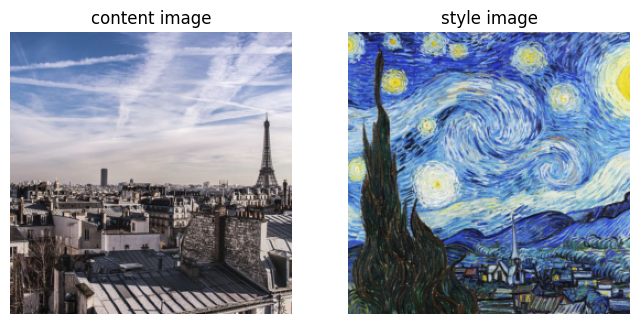

In [42]:
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# ---- Images: the example images from the lecture, stored in the course repository ----
import os, urllib.request
from PIL import Image

REPO = 'https://raw.githubusercontent.com/klaverhenrik/Deep-Learning-for-Visual-Recognition-2026/main/data/'
os.makedirs('images', exist_ok=True)


def get_image(name):
    path = os.path.join('images', name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(REPO + name, path)
    return Image.open(path).convert('RGB')


SIZE = 256


def load_image(name, size=SIZE):
    # Pixels in [0, 1]; the normalisation happens inside get_features
    return T.Compose([T.Resize(size), T.CenterCrop(size), T.ToTensor()])(get_image(name)).unsqueeze(0).to(device)


def show(x, ax=None, title=None):
    ax = ax or plt.gca()
    ax.imshow(x[0].detach().clamp(0, 1).permute(1, 2, 0).cpu()); ax.axis('off')
    if title:
        ax.set_title(title)


# ---- VGG16 (features only), with average pooling instead of max pooling (lecture, Section 8.1) ----
vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.IMAGENET1K_V1).features
for i, layer in enumerate(vgg):
    if isinstance(layer, nn.MaxPool2d):
        vgg[i] = nn.AvgPool2d(2, 2)
    elif isinstance(layer, nn.ReLU):
        layer.inplace = False
vgg = vgg.to(device).eval()
for p in vgg.parameters():
    p.requires_grad_(False)
normalise = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

STYLE_LAYERS = {1: 'relu1_1', 6: 'relu2_1', 11: 'relu3_1', 18: 'relu4_1', 25: 'relu5_1'}
CONTENT_LAYER = 20                                          # relu4_2


def get_features(x, layers):
    # Run VGG16 up to the deepest requested layer, and return the activations of the requested layers
    feats, h = {}, normalise(x)
    for i, layer in enumerate(vgg):
        h = layer(h)
        if i in layers:
            feats[i] = h
        if i == max(layers):
            break
    return feats


def features_at(x, layer):
    return get_features(x, [layer])[layer]                  # the feature maps of one layer, shape (1, C, H, W)


def as_matrix(feature_map):
    _, C, H, W = feature_map.shape
    return feature_map.reshape(C, H * W)                    # one row per channel: shape (C, H*W)


def mse(a, b):
    return ((a - b) ** 2).mean()                            # mean of the squared differences of all entries


content_img = load_image('paris.jpg')
style_img = load_image('starry_night.jpg')
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
show(content_img, axs[0], 'content image'); show(style_img, axs[1], 'style image')
plt.show()

The setup cell defines a few **helper functions**, so that the code in the tasks reads like the lecture's
equations:

| Helper | Returns |
|---|---|
| `get_features(x, layers)` | a dictionary {layer: feature maps of image `x` at that layer} |
| `features_at(x, layer)` | the feature maps of one layer, shape (1, C, H, W) |
| `as_matrix(feature_map)` | the feature maps reshaped to a matrix with one row per channel, shape (C, H·W) |
| `mse(a, b)` | the mean of the squared differences of all entries of `a` and `b` |

> The lecture's code uses VGG19; any VGG network works. We use VGG16, so the layer indices differ from the
> lecture notes (here `relu4_2` is `features[20]`).

---
# Part 1 — The Gram matrix

For a feature map with $C$ channels and $H \times W$ positions, reshape it to a matrix
$\mathbf{F}$ of shape $(C, HW)$: one row per channel. The Gram matrix is

$$\mathbf{G} = \frac{1}{CHW}\,\mathbf{F}\mathbf{F}^\top, \qquad G_{kk'} = \frac{1}{CHW}\sum_{\text{positions } p} F_{kp}\,F_{k'p}.$$

$G_{kk'}$ is large if channels $k$ and $k'$ are active **at the same positions**: it measures which features
occur *together*, summed over the whole image.

### 🛠️ TASK 1a: Implement the Gram matrix

| Lecture | Code |
|---|---|
| $\mathbf{F}$, shape $(C, HW)$ | `Fm = as_matrix(feature_map)` (given) |
| $\mathbf{F}^\top$ | `Fm.T` |
| matrix product $\mathbf{A}\mathbf{B}$ | `A @ B` |
| $C$, $H$, $W$ | `C`, `H`, `W` (given) |

In [43]:
def gram_matrix(feature_map):
    # feature_map: (1, C, H, W)  ->  (C, C)
    _, C, H, W = feature_map.shape
    Fm = as_matrix(feature_map)                      # F: shape (C, H*W)
    return Fm @ Fm.T / (C * H * W)                   # G = F F^T / (C H W)

In [44]:
# Test for Task 1a
_fm = features_at(content_img, 11)
_G = gram_matrix(_fm)
assert _G.shape == (_fm.shape[1], _fm.shape[1]), 'the Gram matrix should be C x C'
assert torch.allclose(_G, _G.T), 'the Gram matrix must be symmetric'
print('✅ Task 1a passed')

✅ Task 1a passed


### ✍️ TASK 1b: Does the Gram matrix care *where* features are? (Predict first)

The cell below takes the `relu3_1` feature maps of the content image and **shuffles their spatial
positions**: the same random permutation of the $H \times W$ positions for every channel, as if the image
had been cut into tiny pieces and put back together in a random order. Then it compares the original and
the shuffled version.

Before you run it, predict: will the **feature maps** change? Will the **Gram matrix** change?

In [45]:
fm = features_at(content_img, 11)                                # (1, C, H, W)
perm = torch.randperm(fm.shape[2] * fm.shape[3], device=device)
fm_shuffled = fm.flatten(2)[:, :, perm].view_as(fm)              # the same feature map with its positions shuffled by perm

print(f'mean |difference| of the feature maps:  {(fm - fm_shuffled).abs().mean().item():.4f}')
print(f'mean |difference| of the Gram matrices: {(gram_matrix(fm) - gram_matrix(fm_shuffled)).abs().mean().item():.2e}')

mean |difference| of the feature maps:  0.8817
mean |difference| of the Gram matrices: 1.57e-10


### Does the Gram matrix capture "style"?

We cut 128×128 crops from three images: two from *The Starry Night*, two from the photo of Paris and one
from the cat, and compare every pair in two ways at `relu3_1`: by the distance between their **feature
maps** (which depends on *what is where*), and by the distance between their **Gram matrices**.

✍️ **Prediction:** which crops will be close to each other in each of the two measures?

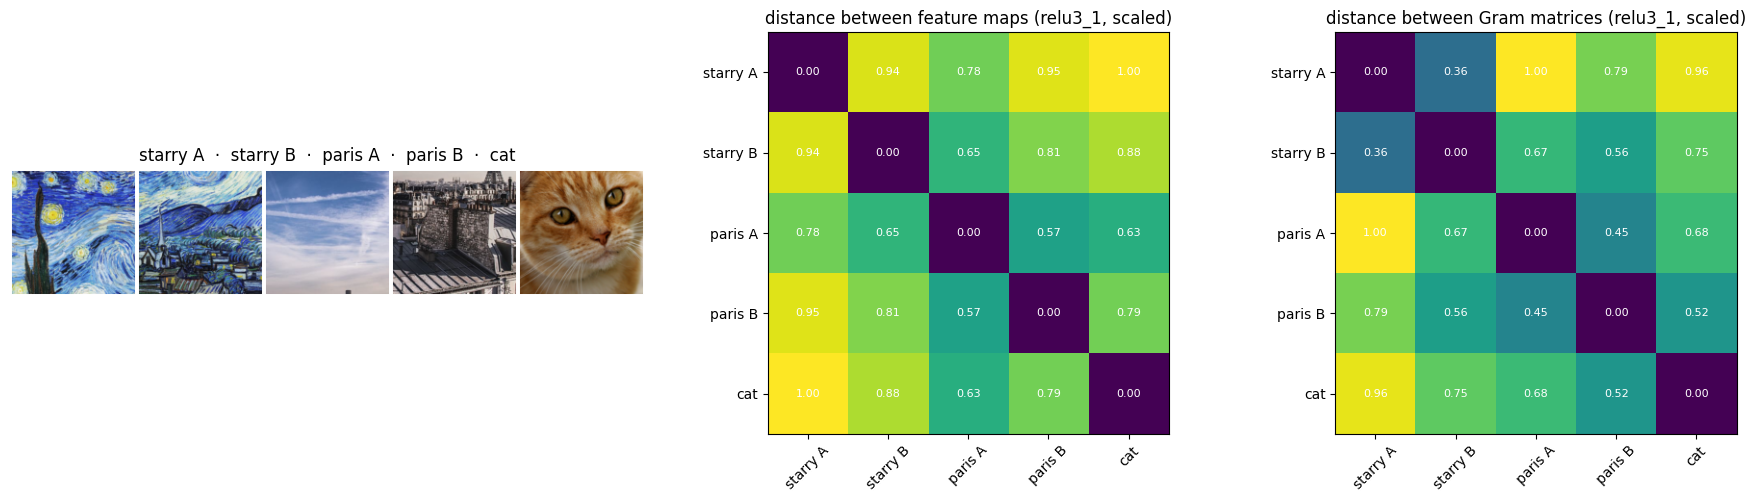

In [46]:
cat_img = load_image('Cat03.jpg')
crops = {'starry A': style_img[..., :128, :128], 'starry B': style_img[..., 128:, 128:],
         'paris A': content_img[..., :128, :128], 'paris B': content_img[..., 128:, 128:],
         'cat': cat_img[..., 64:192, 64:192]}
feats = {k: get_features(v, [11])[11] for k, v in crops.items()}
names = list(crops)
D_feat = np.array([[((feats[a] - feats[b]) ** 2).mean().item() for b in names] for a in names])
D_gram = np.array([[((gram_matrix(feats[a]) - gram_matrix(feats[b])) ** 2).mean().item() for b in names] for a in names])

fig, axs = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.3, 1, 1]})
show(torch.cat([F.pad(c, (2, 2, 2, 2), value=1) for c in crops.values()], dim=3), axs[0], '  ·  '.join(names))
for ax, D, title in [(axs[1], D_feat, 'distance between feature maps'), (axs[2], D_gram, 'distance between Gram matrices')]:
    ax.imshow(D / D.max(), cmap='viridis')
    ax.set_xticks(range(5)); ax.set_xticklabels(names, rotation=45); ax.set_yticks(range(5)); ax.set_yticklabels(names)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f'{D[i, j] / D.max():.2f}', ha='center', va='center', color='w', fontsize=8)
    ax.set_title(title + ' (relu3_1, scaled)')
plt.tight_layout(); plt.show()

### Questions 1

1. Explain in your own words why shuffling the positions does not change the Gram matrix. Which
   information does the Gram matrix keep, and which does it throw away?
2. In the distance matrices, which pairs are close in Gram-matrix distance but far apart in feature-map
   distance? What does that tell you about what the Gram matrix measures?
3. Two photos of the same brick wall, with the bricks in different positions: similar or different Gram
   matrices? Similar or different feature maps?

> ### ✅ Solution and discussion
> 1. Each entry $G_{kk'}$ is a **sum over all positions** of the product of two channels at the same position.
>    A sum doesn't depend on the order of its terms, and shuffling moves the same pairs of values $(F_{kp}, F_{k'p})$
>    to other positions without separating them. So the Gram matrix keeps **which features occur, how strongly
>    and which occur together**, and throws away **where** they occur.
> 2. The clearest case is the two *Starry Night* crops: they show different parts of the painting, so their feature
>    maps are **further apart than almost any other pair** (0.94 on the scaled distance in the reference run), yet their
>    Gram matrices are the **closest** pair (0.36): same brushstrokes, same colours, same swirls. The two Paris crops
>    (sky vs. rooftops) contain genuinely different textures, so they are less close in Gram distance (0.45), though
>    still each other's nearest neighbour. The Gram matrix measures texture/style statistics, not content; it is not a
>    perfect "same image" detector, because one photo can contain several textures.
> 3. Similar Gram matrices (same textures and feature co-occurrences), different feature maps (the bricks are in
>    different places).

---
# Part 2 — Texture synthesis

Start from noise, and change the image until its Gram matrices match those of a texture image, at several
layers (lecture, Section 7.2):

$$\mathcal{L}_\text{style}(\mathbf{y}) = \sum_{l} \left\| \mathbf{G}^l(\mathbf{y}) - \mathbf{G}^l(\mathbf{x}) \right\|^2 \quad \text{(mean of the squared differences of the entries).}$$

We use the **L-BFGS** optimiser, as the lecture's style-transfer code does: it uses information about the
curvature of the loss and converges in far fewer steps than Adam for this kind of problem. Its only quirk in
PyTorch: `step()` takes a function (a *closure*) that recomputes the loss, because L-BFGS may evaluate the loss
several times per step.

### 🛠️ TASK 2a: The style loss

Complete the term inside the sum over layers.

| Lecture | Code |
|---|---|
| $\mathbf{G}^l(\mathbf{y})$: the Gram matrix of the generated image at layer $l$ | `gram_matrix(feats[l])` |
| $\mathbf{G}^l(\mathbf{x})$: the Gram matrix of the texture image (computed once) | `target_grams[l]` |
| $\|\mathbf{A} - \mathbf{B}\|^2$ (mean of the squared differences) | `mse(A, B)` |

In [47]:
def run_lbfgs(loss_fn, x_init, steps=200):
    x = x_init.clone().requires_grad_(True)
    opt = torch.optim.LBFGS([x], max_iter=20)
    for _ in range(max(1, steps // 20)):
        def closure():
            with torch.no_grad():
                x.clamp_(0, 1)                               # keep the pixels valid
            opt.zero_grad()
            loss = loss_fn(x)
            loss.backward()
            return loss
        opt.step(closure)
    return x.detach().clamp(0, 1)

In [48]:
def style_loss(x, target_grams):
    # target_grams: {layer index: Gram matrix of the style image at that layer}
    feats = get_features(x, list(target_grams))
    loss = 0
    for l in target_grams:
        loss = loss + mse(gram_matrix(feats[l]), target_grams[l])   # || G^l(y) - G^l(x) ||^2
    return loss

In [49]:
# Test for Task 2a
_tg = {l: gram_matrix(f) for l, f in get_features(style_img, [1, 6]).items()}
assert style_loss(style_img, _tg).item() < 1e-10, 'the style loss of the style image itself must be 0'
assert style_loss(content_img, _tg).item() > 0
print('✅ Task 2a passed')

✅ Task 2a passed


### Synthesise textures from *The Starry Night*

We match the Gram matrices of increasingly many layers: only `relu1_1`; `relu1_1` to `relu3_1`; and all
five style layers.

✍️ **Prediction:** how will the three textures differ?

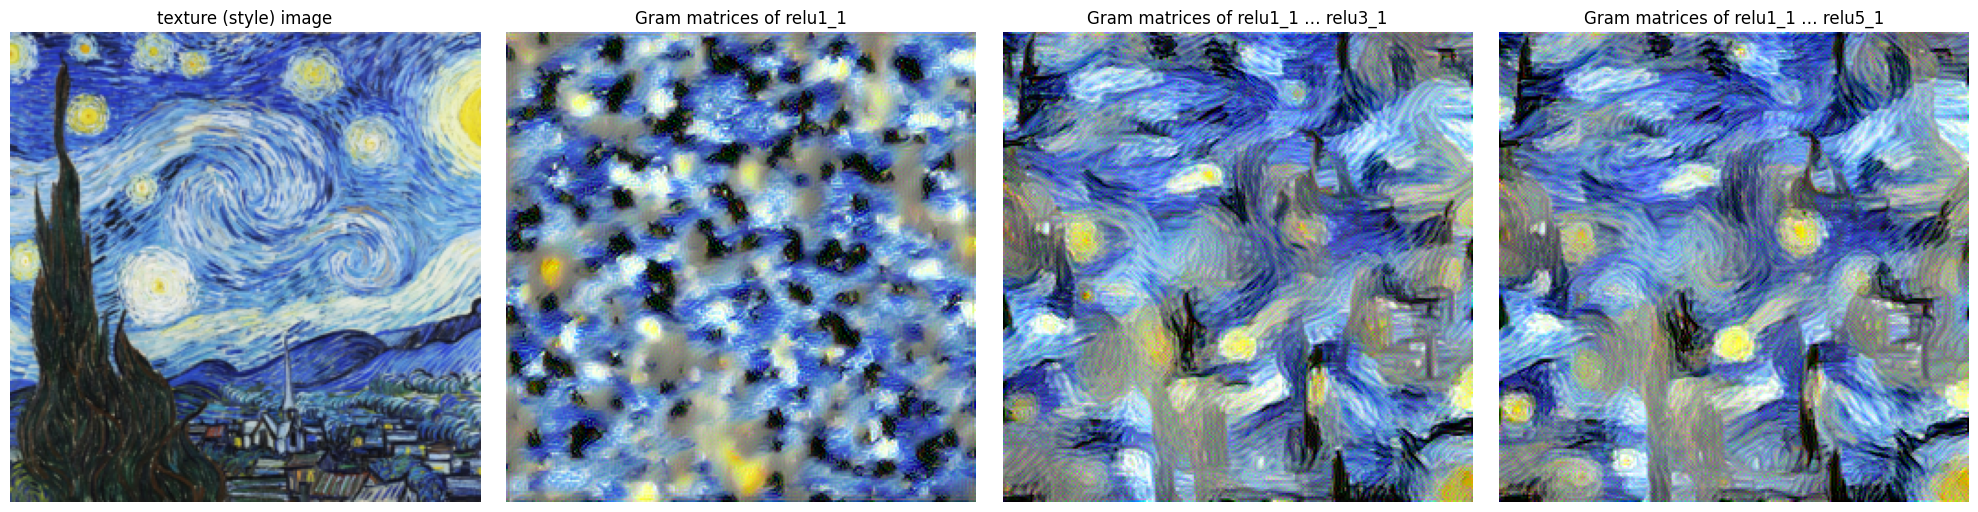

Time: 16 s


In [50]:
layer_sets = {'relu1_1': [1], 'relu1_1 … relu3_1': [1, 6, 11], 'relu1_1 … relu5_1': [1, 6, 11, 18, 25]}
t0 = time.time()
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
show(style_img, axs[0], 'texture (style) image')
for ax, (name, layers) in zip(axs[1:], layer_sets.items()):
    targets = {l: gram_matrix(f) for l, f in get_features(style_img, layers).items()}
    torch.manual_seed(0)
    texture = run_lbfgs(lambda x: 1e6 * style_loss(x, targets), torch.rand_like(style_img), steps=200)
    show(texture, ax, f'Gram matrices of {name}')
plt.tight_layout(); plt.show()
print(f'Time: {time.time() - t0:.0f} s')

### Questions 2

1. Describe the three textures. What does adding deeper layers change?
2. Do the textures contain the village, the church or the cypress tree of the painting in recognisable form?
   Why (not)?

> ### ✅ Solution and discussion
> 1. With only `relu1_1`, the result is mainly the colour palette in small blobs: the first layer only describes
>    colours and tiny edges. Adding `relu2_1` and `relu3_1` adds brushstrokes, curved strokes and bright star-like
>    spots. Adding `relu4_1` and `relu5_1` changes less here (slightly larger, more coherent swirls): the larger
>    receptive fields of the deeper layers describe coarser structures. The choice of layers sets the **scale** of the
>    texture that is reproduced.
> 2. No: elements of the painting appear as texture (dark, flame-like shapes; bright blobs that resemble stars),
>    but scattered over the image, without the composition of the painting. The Gram matrices contain no
>    information about *where* things are (Part 1), so the synthesis can only reproduce local statistics, not the
>    layout.

---
# Part 3 — Neural style transfer

Combine a **content loss** (match the feature map of the photo at `relu4_2`, which keeps *what is where*)
with the **style loss** (match the Gram matrices of the painting at all five style layers):

$$\mathcal{L}_\text{content}(\mathbf{y}, \text{photo}) = \big\|\mathbf{a}^{l}(\mathbf{y}) - \mathbf{a}^{l}(\text{photo})\big\|^2 \quad (l = \texttt{relu4\_2}),$$

$$\mathcal{L}_\text{total} = \alpha\, \mathcal{L}_\text{content}(\mathbf{y}, \text{photo}) + \beta\, \mathcal{L}_\text{style}(\mathbf{y}, \text{painting}).$$

Following the lecture, we start from the **content image** (instead of noise), which converges faster.

### 🛠️ TASK 3a: The content loss and the total loss

| Lecture | Code |
|---|---|
| $\mathbf{a}^{l}(\mathbf{y})$ at $l$ = `relu4_2` | `features_at(x, CONTENT_LAYER)` |
| $\mathbf{a}^{l}(\text{photo})$ (computed once) | `content_target` |
| $\|\mathbf{A} - \mathbf{B}\|^2$ (mean of the squared differences) | `mse(A, B)` |
| $\mathcal{L}_\text{style}(\mathbf{y}, \text{painting})$ | `style_loss(x, style_targets)` |
| $\alpha$, $\beta$ | `alpha`, `beta` |

In [51]:
content_target = features_at(content_img, CONTENT_LAYER)
style_targets = {l: gram_matrix(f) for l, f in get_features(style_img, list(STYLE_LAYERS)).items()}


def content_loss(x):
    return mse(features_at(x, CONTENT_LAYER), content_target)      # L_content: || a^l(y) - a^l(photo) ||^2


def style_transfer(alpha=1.0, beta=1e6, steps=200):
    loss_fn = lambda x: alpha * content_loss(x) + beta * style_loss(x, style_targets)   # L_total
    return run_lbfgs(loss_fn, content_img, steps)

### The trade-off between content and style

We run style transfer with four values of the style weight $\beta$ (and $\alpha = 1$), and for each result
we measure **both** losses.

✍️ **Prediction:** sketch how the content loss and the style loss of the result change as $\beta$ grows.

Time: 56 s

    beta   content loss   style loss
   1e+03          0.002     2.88e-06
   1e+05          0.019     2.76e-07
   1e+06          0.100     7.08e-08
   1e+07          0.281     1.35e-08


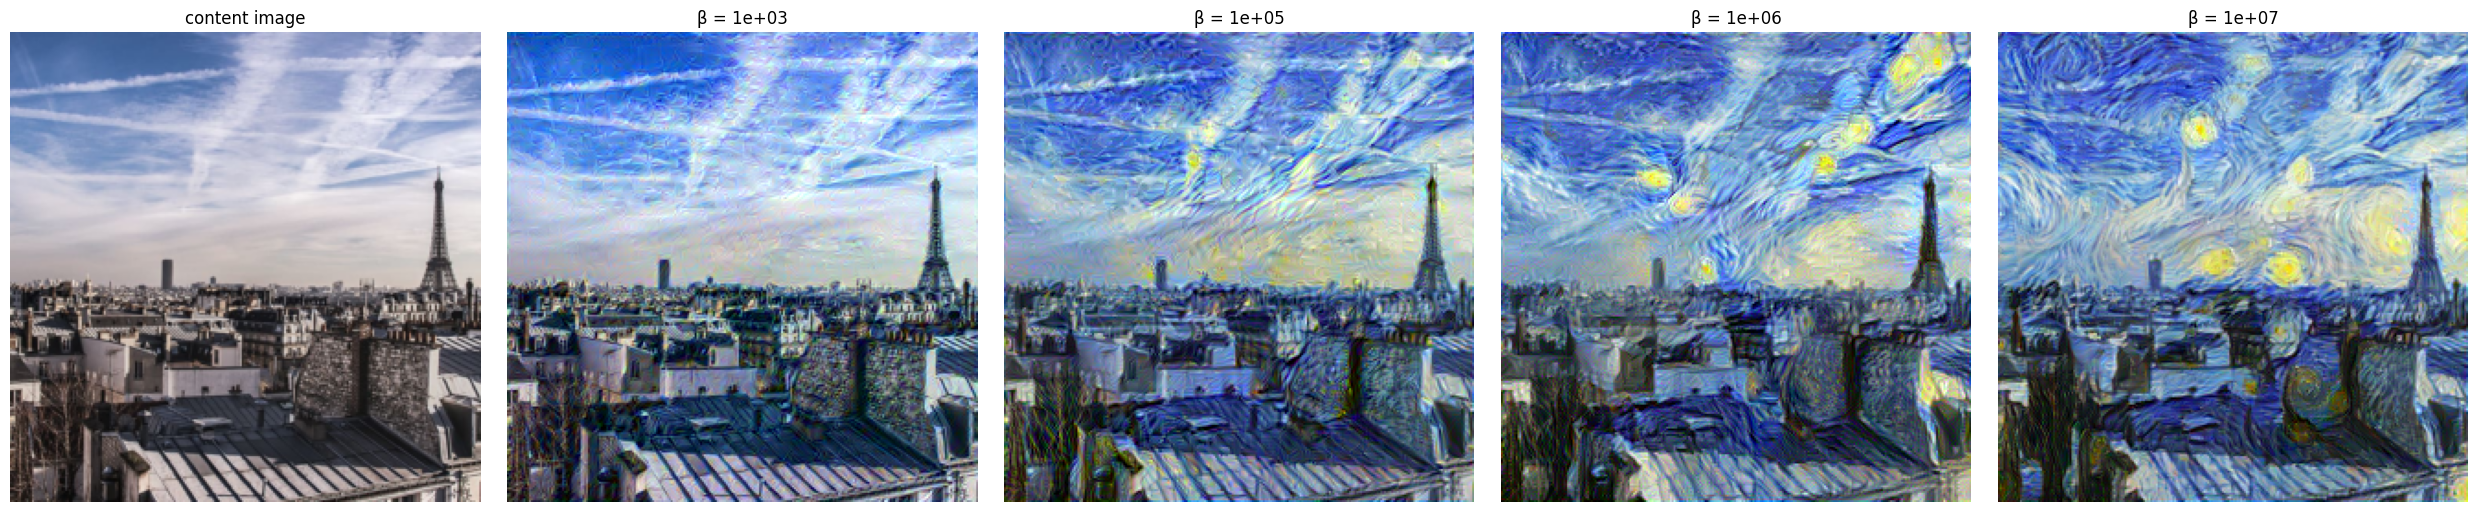

In [52]:
betas = [1e3, 1e5, 1e6, 1e7]
results = {}
t0 = time.time()
for beta in betas:
    y = style_transfer(beta=beta)
    with torch.no_grad():
        results[beta] = (y, content_loss(y).item(), style_loss(y, style_targets).item())
print(f'Time: {time.time() - t0:.0f} s\n')

print(f'{"beta":>8s} {"content loss":>14s} {"style loss":>12s}')
for beta, (_, lc, ls) in results.items():
    print(f'{beta:8.0e} {lc:14.3f} {ls:12.2e}')
fig, axs = plt.subplots(1, len(betas) + 1, figsize=(5 * (len(betas) + 1), 5))
show(content_img, axs[0], 'content image')
for ax, (beta, (y, lc, ls)) in zip(axs[1:], results.items()):
    show(y, ax, f'β = {beta:.0e}')
plt.tight_layout(); plt.show()

### Questions 3

1. **Mechanism:** how do the two losses of the result change with $\beta$? Is this what you predicted?
2. **Outcome:** which result do *you* find best? Does it have the lowest style loss, or the lowest content loss?
   What does this say about using the loss as a measure of quality here?
3. Why is the content loss computed on `relu4_2` and not on the pixels? What would you expect with a content
   layer like `relu1_2`? (Try it: set `CONTENT_LAYER = 3` and rerun Task 3a with one value of $\beta$.)
4. The lecture recommends average pooling instead of max pooling for style transfer. Why does that give
   smoother results? (Think about the gradient of a max-pool: which of the four pixels in a 2×2 window gets a
   gradient?)

> ### ✅ Solution and discussion
> 1. As $\beta$ grows, the style loss of the result goes **down** (in the reference run from 2.9e-6 to 1.3e-8) and the
>    content loss goes **up** (from 0.002 to 0.28): the two terms compete, and $\beta/\alpha$ sets where on the trade-off curve the result lands. For a small $\beta$ the result is
>    almost the photo with a faint texture; as $\beta$ grows, the sky fills with swirls and yellow "stars", and the
>    rooftops take on the painting's colours and strokes. In the reference run, the buildings are still recognisable at
>    $\beta = 10^7$; a larger $\beta$ would dissolve them further.
> 2. Most people prefer an intermediate value: neither the lowest style loss nor the lowest content loss. Both losses
>    are proxies for what we want ("looks like this painting", "shows this scene"), and no single loss value
>    measures the aesthetic quality. The same lesson as in Labs 7 and 9: the mechanism (the loss goes down) is not
>    the outcome we care about.
> 3. The pixels would force the result to reproduce the photo's exact colours and textures, leaving no room for the
>    style. `relu4_2` encodes *what is where* (the layout of the buildings), but is invariant to exact colours and
>    fine textures (10A, layer inversion), so the style can change those. With `relu1_2` as content layer, the
>    result stays close to the photo pixel by pixel, and the style is barely visible.
> 4. In a max pool, only the largest of the four values in each window gets a gradient; the other three get zero.
>    The gradient that reaches the image is therefore sparse and blocky, which produces artefacts. An average pool
>    passes a quarter of the gradient to every pixel of the window, so the gradient, and the result, are smoother.

### Bonus: your own photo

In Colab, you can upload your own photo (or one of your project images) and use it as the content image:

```python
from google.colab import files
name = list(files.upload())[0]
content_img = T.Compose([T.Resize(SIZE), T.CenterCrop(SIZE), T.ToTensor()])(Image.open(name).convert('RGB')).unsqueeze(0).to(device)
content_target = features_at(content_img, CONTENT_LAYER)
show(style_transfer(beta=1e6))
```

---
# Part 4 — Exam-style questions

**Q1.** A feature map has 256 channels and spatial size 32×32. What is the shape of its Gram matrix?

* (a) 32×32 · (b) 256×1024 · (c) 256×256 · (d) 1024×1024

**Q2.** Why does the Gram matrix describe texture but not content?

* (a) Because it is computed on the first layer only.
* (b) Because it sums over all positions: it keeps which features co-occur, but not where they are.
* (c) Because it is symmetric.
* (d) Because it uses average pooling.

**Q3.** In neural style transfer, what is optimised?

* (a) The weights of VGG.
* (b) The Gram matrices of the style image.
* (c) The pixels of the generated image.
* (d) The content image.

**Q4.** The style weight β is increased by a factor 100. What happens to the result?

* (a) It looks more like the photo.
* (b) It looks more like the painting's texture, and the content becomes harder to recognise.
* (c) Nothing, because the losses are normalised.
* (d) The optimisation no longer converges.

> ### ✅ Solution and discussion
> * **Q1: (c).** $C \times C$.
> * **Q2: (b).**
> * **Q3: (c).** VGG is frozen; the style image's Gram matrices are fixed targets.
> * **Q4: (b).**